# Accuracy comparison across FedAvg variants

Loads the per-round global test accuracy histories saved by the five training
notebooks and plots them on one chart:

- `duz_egitim.ipynb` -> `acc_history_clean_baseline.npy` (no malicious clients)
- `1_user_atmasiz.ipynb` -> `acc_history_1_malicious_no_exclude.npy` (1 malicious, never excluded)
- `1_user_atmali.ipynb` -> `acc_history_1_malicious_detect_exclude.npy` (1 malicious, detected & excluded)
- `2_user_atmasiz.ipynb` -> `acc_history_2_malicious_no_exclude.npy` (2 malicious, never excluded)
- `fed_learning.ipynb` -> `acc_history_detect_exclude.npy` (2 malicious, detected & excluded)

Run those five notebooks first so their `.npy` files exist in `UnreliableClientsinFL/`.

In [1]:
import os
noise_var_name = '001'
noise_var = "0.01"
user_size = 16
repo_dir = os.path.join(os.getcwd(), 'UnreliableClientsinFL', f'{noise_var_name}_{user_size}')
os.chdir(repo_dir)
print("Working directory:", os.getcwd())

Working directory: C:\Users\osman\Documents\yl\UnreliableClientsinFL\001_16


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np

runs = [
    (
        "Clean baseline (no malicious)",
        "acc_history_clean_baseline.npy",
        "#2a78d6",
        "o",
    ),  # Circle
    (
        "1 malicious, not excluded",
        "acc_history_1_malicious_no_exclude.npy",
        "#eb6834",
        "s",
    ),  # Square
    (
        "1 malicious, detected & excluded",
        "acc_history_1_malicious_detect_exclude.npy",
        "#1baf7a",
        "D",
    ),  # Diamond
    (
        "2 malicious, not excluded",
        "acc_history_2_malicious_no_exclude.npy",
        "#eda100",
        "^",
    ),  # Triangle up
    (
        "2 malicious, detected & excluded",
        "acc_history_detect_exclude.npy",
        "#e87ba4",
        "v",
    ),  # Triangle down
]

histories = {}
missing = []
for label, fname, color, marker in runs:
    if os.path.exists(fname):
        histories[label] = (np.load(fname), color, marker)
    else:
        missing.append(fname)

if missing:
    print("Missing (run the corresponding notebook first):")
    for m in missing:
        print(" -", m)

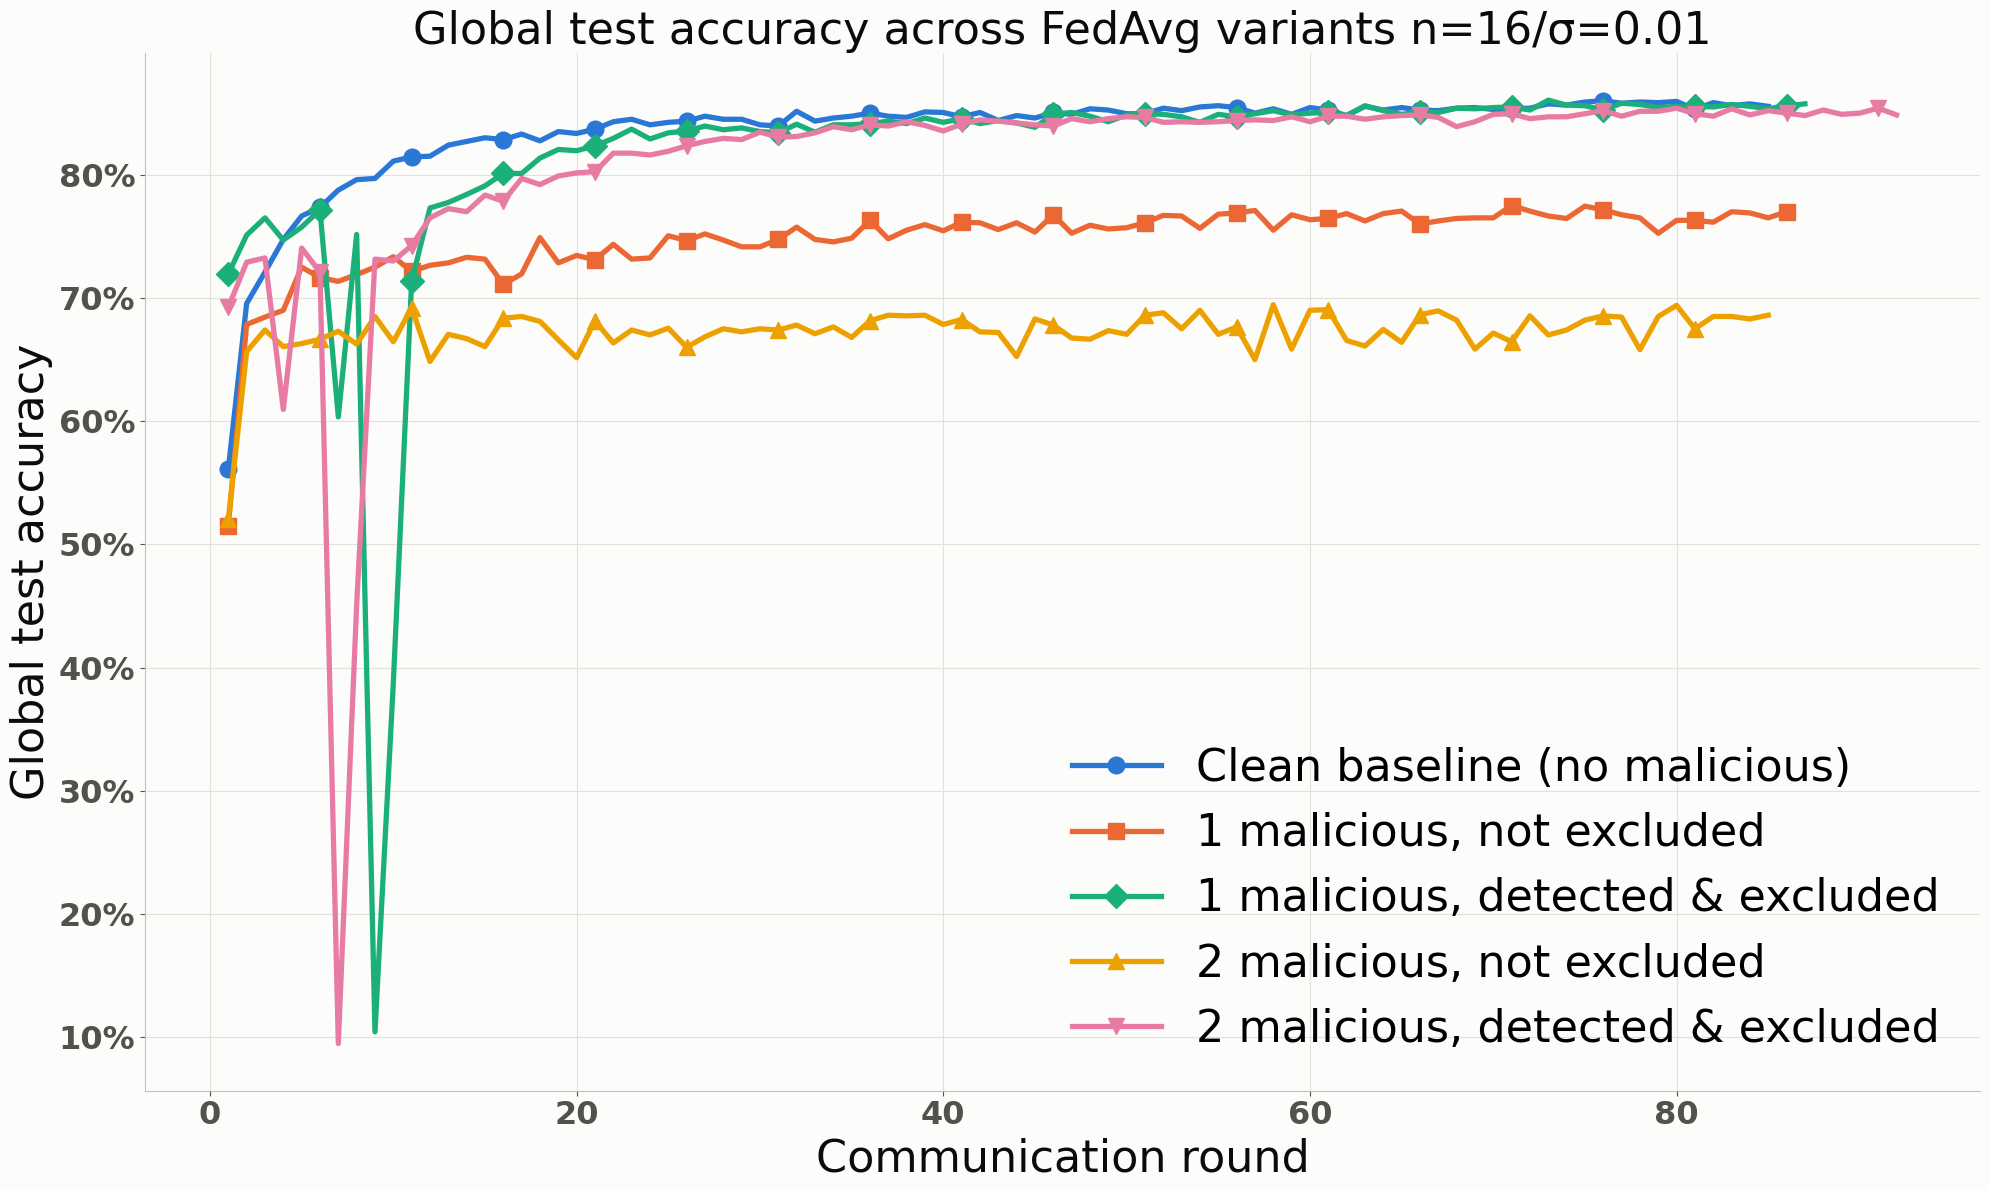

In [3]:
fig, ax = plt.subplots(figsize=(20, 12), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

for label, (acc, color, marker) in histories.items():
    rounds = np.arange(1, len(acc) + 1)
    ax.plot(
        rounds,
        acc,
        label=label,
        color=color,
        marker=marker,
        markersize=12,  # Adjust marker size to fit large fonts
        markevery=5,  # Show marker every 5 rounds (adjust as needed)
        linewidth=3.8,
    )

ax.set_xlabel("Communication round", color="#0b0b0b", fontsize=32)
ax.set_ylabel("Global test accuracy", color="#0b0b0b", fontsize=32)
ax.set_title(
    f"Global test accuracy across FedAvg variants n={user_size}/σ={noise_var}", color="#0b0b0b", fontsize=32
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#c3c2b7")
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e", labelsize=23)
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
ax.legend(frameon=False, fontsize=32)
fig.tight_layout()
fig.savefig("acc_comparison.png", dpi=150)
plt.show()

In [4]:
print(f"{'Run':40s} {'Rounds':>7s} {'Final acc':>10s} {'Best acc':>10s}")
for label, (acc, _color, _marker) in histories.items():
    print(f"{label:40s} {len(acc):7d} {acc[-1]*100:9.2f}% {max(acc)*100:9.2f}%")

Run                                       Rounds  Final acc   Best acc
Clean baseline (no malicious)                 85     85.55%     86.00%
1 malicious, not excluded                     86     77.00%     77.50%
1 malicious, detected & excluded              87     85.75%     86.05%
2 malicious, not excluded                     85     68.60%     69.45%
2 malicious, detected & excluded              92     84.85%     85.40%


## Separate plots per malicious-client count

Same data as above, split into two charts so each attack scenario (1 vs 2 malicious clients) is compared against the clean baseline on its own.

In [5]:
def plot_group(title, labels, filename, search_rounds=None):
    fig, ax = plt.subplots(figsize=(20, 12), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")

    if search_rounds is not None:
        max_round = max(len(histories[label][0]) for label in labels)
        ax.axvspan(0, search_rounds, color="gold", alpha=0.15, label="Search (malicious detection)", zorder=0)
        ax.axvspan(search_rounds, max_round, color="green", alpha=0.1, label="Training", zorder=0)

    for label in labels:
        acc, color, marker = histories[label]
        rounds = np.arange(1, len(acc) + 1)
        ax.plot(rounds, acc, label=label, color=color, marker=marker,
                markersize=12, markevery=5, linewidth=3.8)

    ax.set_xlabel("Communication round", color="#0b0b0b", fontsize=32)
    ax.set_ylabel("Global test accuracy", color="#0b0b0b", fontsize=32)
    ax.set_title(title, color="#0b0b0b", fontsize=32)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
    ax.grid(True, color="#e1e0d9", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=23)
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")
    ax.legend(frameon=False, fontsize=32)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

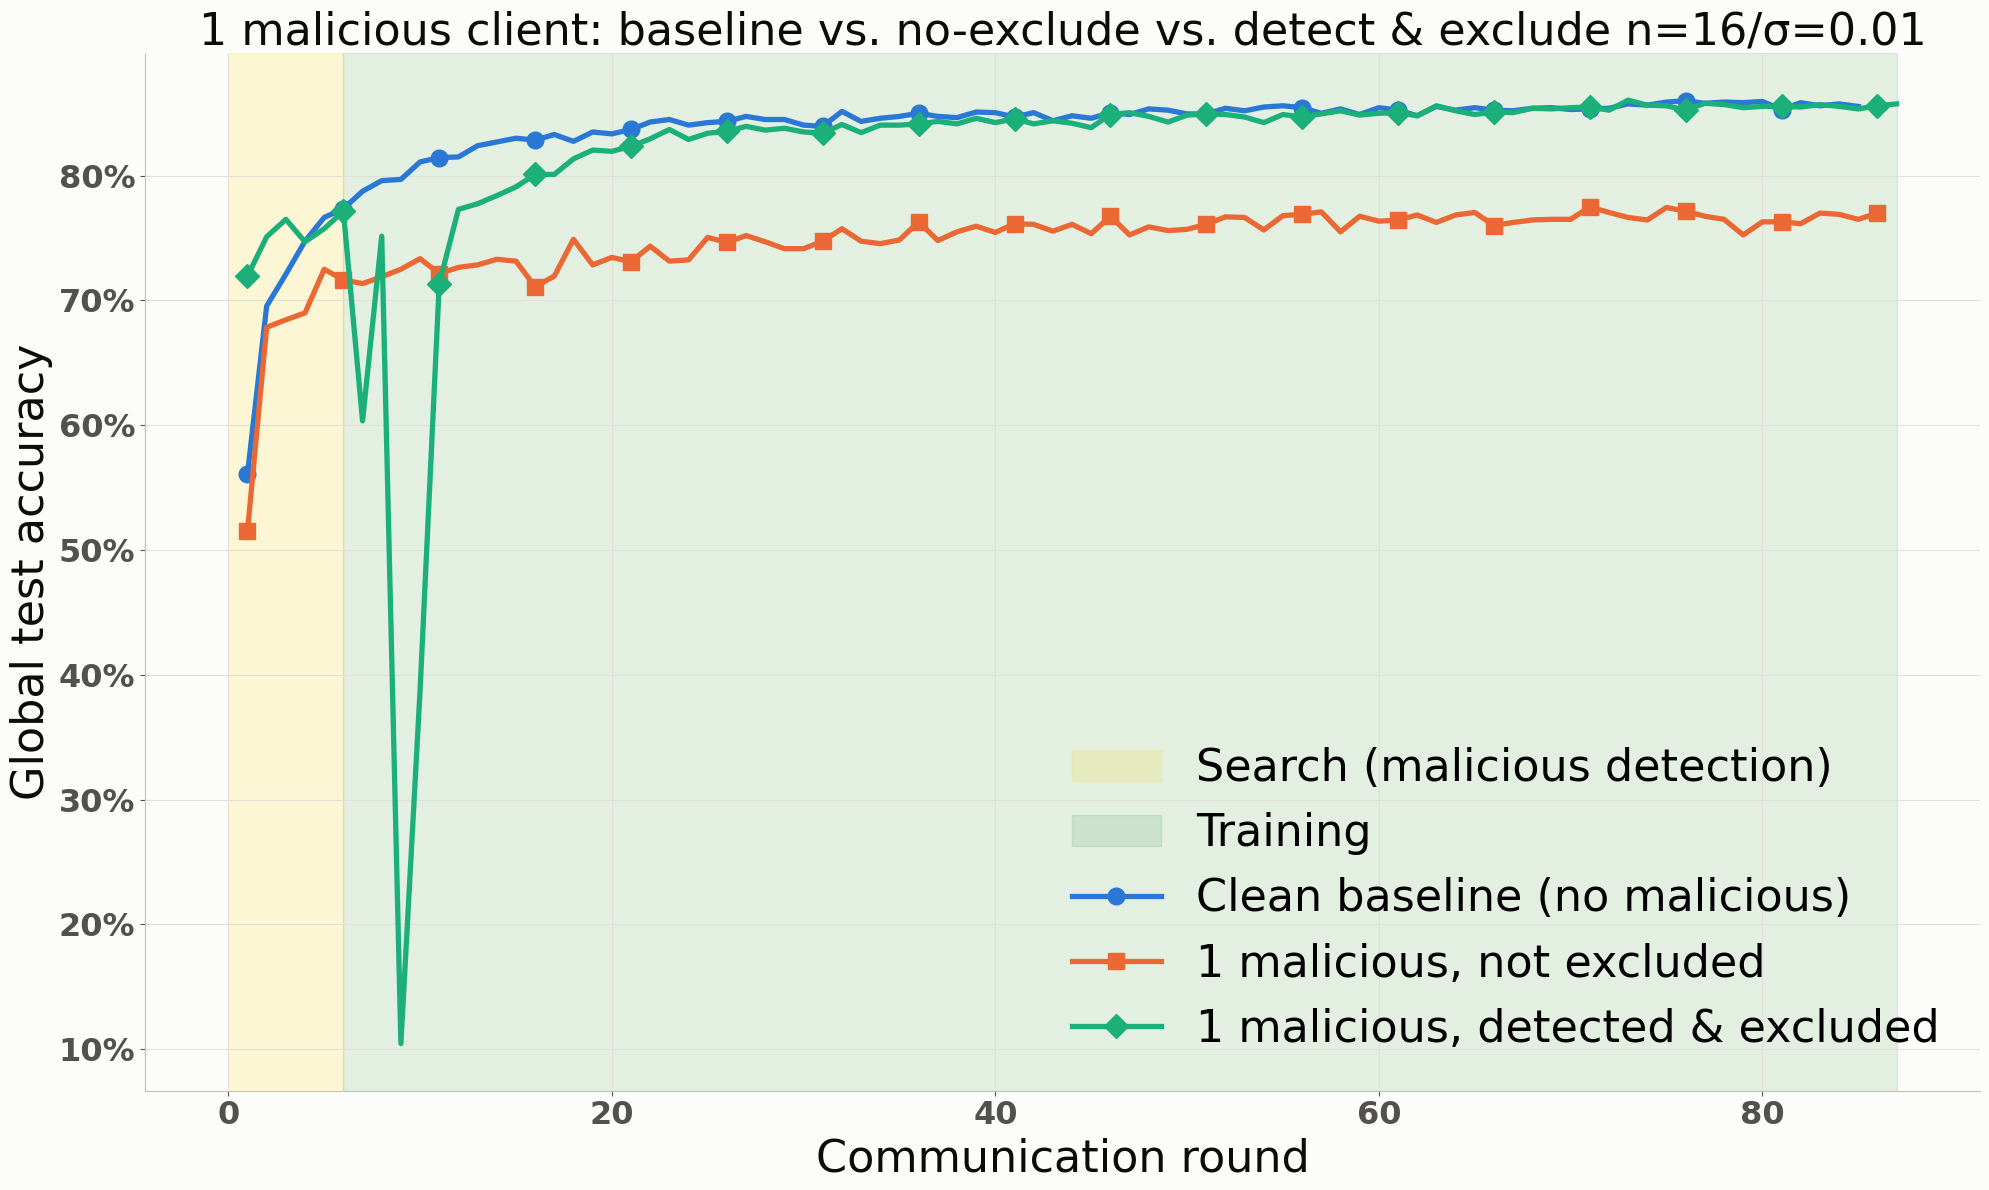

In [6]:
plot_group(
    f"1 malicious client: baseline vs. no-exclude vs. detect & exclude n={user_size}/σ={noise_var}",
    [
        "Clean baseline (no malicious)",
        "1 malicious, not excluded",
        "1 malicious, detected & excluded",
    ],
    "acc_comparison_1_malicious.png",
    search_rounds=6,
)

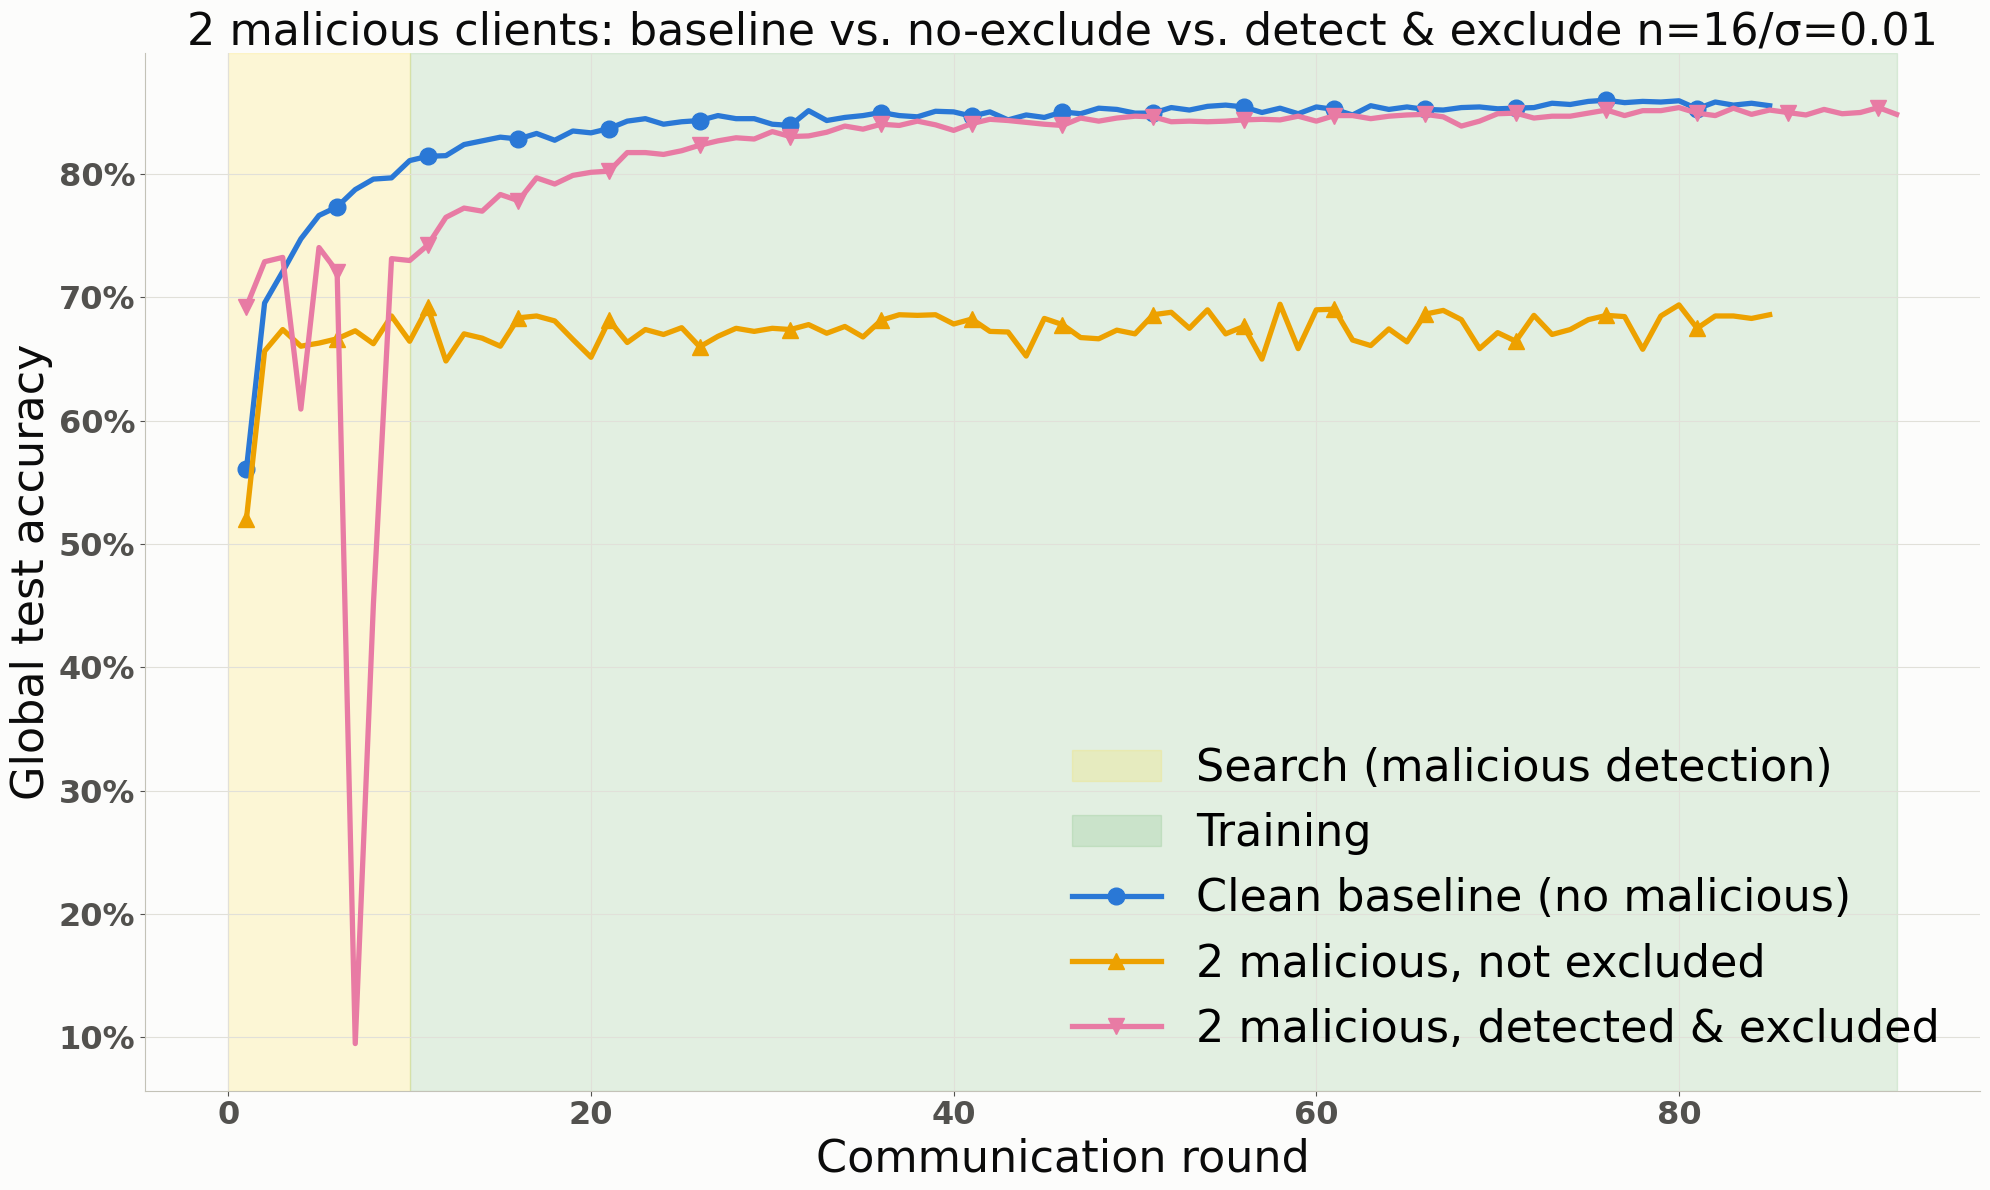

In [7]:
plot_group(
    f"2 malicious clients: baseline vs. no-exclude vs. detect & exclude n={user_size}/σ={noise_var}",
    [
        "Clean baseline (no malicious)",
        "2 malicious, not excluded",
        "2 malicious, detected & excluded",
    ],
    "acc_comparison_2_malicious.png",
    search_rounds=10,
)